# Real-world example

We will now use a more real-world model. For this, we make use of the daily
climate data from the climate station of the Jena Experiment:

```
Huang, Y., Kolle, O., Ebeling, A., & Eisenhauer, N. (2023). Climate data (daily resolution) from the climate station in The Jena Experiment from 2003 to 2022 [Dataset]. Jena Experiment Information System. https://doi.org/10.25829/NCPM-S988 Licensed under CC BY 4.0.
```

Specifically, we will make a neural network that predicts the expected relative
humidity for a given week of the year.

## Training a model

First, we fetch the dataset.


In [1]:
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
import altair as alt
import torch
from util.nn import ReLUFNN, train, load_pytorch_model_into_db

In [2]:
DATASET_PATH = Path("datasets/jena_climate_2003_2022.csv")
MODEL_PATH = Path("models/jena_rh_weekly_2003_2022.pt")
FORCE_RETRAIN = False
PLOT_PATH = Path("jena_weekly.png")


In [3]:
if not DATASET_PATH.exists():
    raise Exception("Dataset is not available, run ./datasets/fetch.sh to retrieve it.")

df = pd.read_csv(DATASET_PATH)
df

,year,month,day,date,p_air,T_air,rh,sh,Tpot,Tdew,...,ST064,ST128,SM008,SM016,SM032,SM064,SM128,Tlog,Heating1,Heating2
0,2003,1,1,1/1/2003 12:00:00 AM,991.8338,-0.6272,87.2672,3.3515,273.1862,-2.5285,...,3.6717,5.8909,35.2111,36.3998,42.4681,44.5347,40.3400,1.2213,54.1849,43.0262
1,2003,1,2,1/2/2003 12:00:00 AM,972.6427,9.6046,82.7277,6.3358,285.0177,6.7498,...,3.6729,5.9392,35.9946,37.5415,42.7746,44.8829,40.4087,10.3552,31.6438,0.0000
2,2003,1,3,1/3/2003 12:00:00 AM,977.2677,8.6873,78.4385,5.6304,283.7098,5.1196,...,3.9331,5.9681,48.0823,49.1408,43.5115,45.3544,40.6006,9.0312,12.6744,0.0000
3,2003,1,4,1/4/2003 12:00:00 AM,988.4079,1.3960,87.9867,3.7994,274.9648,-0.3927,...,4.3827,6.0115,50.8960,51.7958,44.3427,45.6860,40.6300,2.1625,66.1569,5.9950
4,2003,1,5,1/5/2003 12:00:00 AM,994.5852,-2.3794,72.6217,2.3235,271.2023,-6.6785,...,4.7427,6.0819,50.9262,51.8919,44.4492,45.7419,40.5769,-2.1065,0.0000,0.0000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7301,2022,12,28,12/28/2022 12:00:00 AM,999.5050,6.7708,77.0223,4.7352,279.9635,2.9354,...,6.4369,8.2210,38.3842,34.6408,34.8375,31.7271,28.6354,13.4269,13.7500,8.5765
7302,2022,12,29,12/29/2022 12:00:00 AM,991.3367,10.3027,73.8133,5.8227,284.1594,5.7867,...,6.4477,8.2662,37.9125,34.3467,34.6729,31.7104,28.6635,16.7873,6.9215,0.0000
7303,2022,12,30,12/30/2022 12:00:00 AM,995.6335,7.7596,78.3573,5.1815,281.2619,4.1629,...,6.5873,8.2977,37.6165,34.0513,34.4977,31.6202,28.6896,14.3808,23.1023,0.0000
7304,2022,12,31,12/31/2022 12:00:00 AM,994.8754,15.7304,70.7565,7.9154,289.3056,10.3235,...,6.7104,8.3271,37.4315,33.7604,34.3502,31.5377,28.7194,21.4615,1.1923,0.0000


We are only interested in the relative humidity and the date, so let's drop
everything else and parse the date while we're at it.


In [4]:
rh_colname = "rh"

df = df[["date", rh_colname]]
df["date"] = pd.to_datetime(df["date"], format="%m/%d/%Y %I:%M:%S %p")
df = df[df["date"].dt.year.between(2003, 2022)]
df = df.dropna(subset=[rh_colname])

df["year"] = df["date"].dt.year
df["day_of_year"] = df["date"].dt.dayofyear
df["week"] = (df["day_of_year"] - 1) // 7

df


,date,rh,year,day_of_year,week
0,2003-01-01,87.2672,2003,1,0
1,2003-01-02,82.7277,2003,2,0
2,2003-01-03,78.4385,2003,3,0
3,2003-01-04,87.9867,2003,4,0
4,2003-01-05,72.6217,2003,5,0
...,...,...,...,...,...
7300,2022-12-27,76.7046,2022,361,51
7301,2022-12-28,77.0223,2022,362,51
7302,2022-12-29,73.8133,2022,363,51
7303,2022-12-30,78.3573,2022,364,51


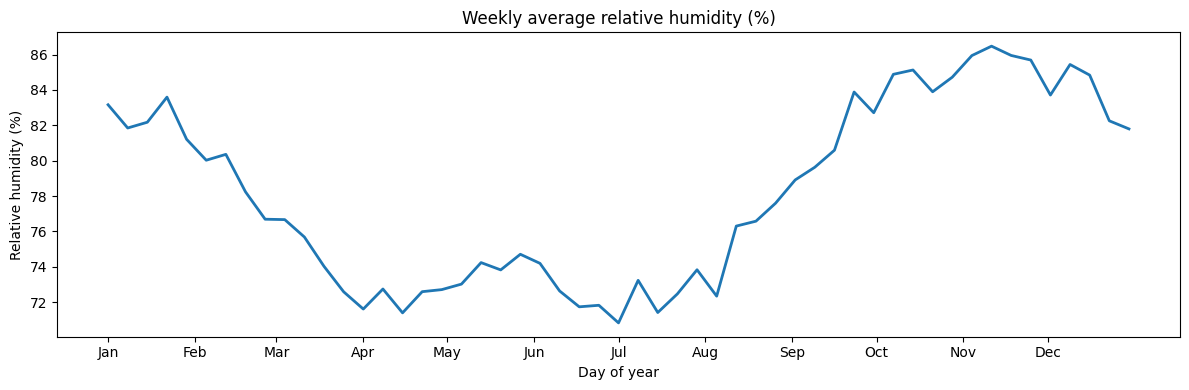

In [5]:
weekly = df.groupby(["year", "week"])[rh_colname].mean().reset_index()
weekly_mean = weekly.groupby("week")[rh_colname].mean()
week_day = weekly_mean.index * 7 + 1

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(week_day, weekly_mean.values, linewidth=2, label="Average")

ax.set_title("Weekly average relative humidity (%)")
ax.set_xlabel("Day of year")
ax.set_ylabel("Relative humidity (%)")
month_starts = pd.to_datetime("2000-" + pd.Index([f"{m:02d}-01" for m in range(1, 13)]))
ax.set_xticks(month_starts.dayofyear)
ax.set_xticklabels(month_starts.strftime("%b"))

plt.tight_layout()
plt.show()


We will train a neural network on the weekly average of the daily sensor values,
using all years as the training data.


In [10]:
x = (weekly["week"] * 7 + 1).to_numpy()
y = weekly[rh_colname].to_numpy()

torch.manual_seed(0)

model = ReLUFNN(input_size=1, hidden_size=50, num_hidden_layers=1, output_size=1)

if MODEL_PATH.exists() and not FORCE_RETRAIN:
    print(f"Reusing saved model {MODEL_PATH}")
    model.load_state_dict(torch.load(MODEL_PATH, weights_only=True))
else:
    if MODEL_PATH.exists():
        print("Deleting existing trained model because FORCE_RETRAIN is set")
        MODEL_PATH.unlink()

    x_mean, x_std = x.mean(), x.std()
    y_mean, y_std = y.mean(), y.std()

    train(
        model,
        (x - x_mean) / x_std,
        (y - y_mean) / y_std,
        epochs=10_000,
    )

    # Fold the normalisation into the first/last layers so the saved model
    # still maps raw day-of-year to raw humidity.
    with torch.no_grad():
        first = model.linear_relu_stack[0]
        first.weight.div_(x_std)
        first.bias.sub_(first.weight.squeeze(1) * x_mean)

        last = model.linear_relu_stack[-1]
        last.weight.mul_(y_std)
        last.bias.mul_(y_std).add_(y_mean)

    torch.save(model.state_dict(), MODEL_PATH)

model.eval()
with torch.no_grad():
    grid = torch.linspace(1, 365, 365).unsqueeze(1)
    prediction = model(grid).squeeze(1).numpy()

week_day = weekly_mean.index * 7 + 1

month_starts = pd.to_datetime("2000-" + pd.Index([f"{m:02d}-01" for m in range(1, 13)]))

# We swap to altair. More work, but consistent with the other graphs in the
# paper.
observed = pd.DataFrame({
    "day_of_year": week_day,
    "humidity": weekly_mean.values,
    "series": "Observed weekly average",
})
predicted = pd.DataFrame({
    "day_of_year": grid.squeeze(1).numpy(),
    "humidity": prediction,
    "series": "Neural network prediction",
})
plot_data = pd.concat([observed, predicted], ignore_index=True)

PRINT_PALETTE = [
    "#0072B2",
    "#D55E00",
    "#009E73",
    "#CC79A7",
    "#E69F00",
    "#56B4E9",
    "#F0E442",
    "#000000",
]

series_domain = ["Observed weekly average", "Neural network prediction"]
month_days = month_starts.dayofyear.tolist()
month_label_expr = " : ".join(
    f"datum.value == {day} ? '{label}'"
    for day, label in zip(month_days, month_starts.strftime("%b"))
) + " : ''"

chart = (
    alt.Chart(plot_data.sort_values("day_of_year"))
    .mark_line(strokeWidth=2)
    .encode(
        x=alt.X(
            "day_of_year:Q",
            title="Day of the year",
            axis=alt.Axis(values=month_days, labelExpr=month_label_expr),
        ),
        y=alt.Y("humidity:Q", title="Relative humidity (%)", scale=alt.Scale(domain=(65, 90))),
        color=alt.Color(
            "series:N",
            title=None,
            scale=alt.Scale(domain=series_domain, range=PRINT_PALETTE[:2]),
            legend=alt.Legend(orient="bottom-right"),
        ),
        strokeDash=alt.StrokeDash(
            "series:N",
            legend=None,
            scale=alt.Scale(domain=series_domain, range=[[6, 3], [1, 0]]),
        ),
    )
    .properties(
        width=600,
        height=260,
    )
    .configure(
        font="serif",
        axis=alt.AxisConfig(labelFontSize=13, titleFontSize=14, grid=False),
        legend=alt.LegendConfig(labelFontSize=13, titleFontSize=14),
        view=alt.ViewConfig(strokeOpacity=0),
    )
)

chart.save(PLOT_PATH, scale_factor=2)
chart


Reusing saved model models/jena_rh_weekly_2003_2022.pt


alt.Chart(...)

## Verifying the model

Now we can start some verification tasks to see if our model behaves as
expected. Since we are dealing with relative humidity, a percentage value, a
first obvious thing is to check if the model always outputs a value between 0
and 100.

In [7]:
import duckdb as db
import util.sqlcad as sqlcad
import util.smtlib as smtlib

DBNAME = "dbs/nnv_jena.db"

with db.connect(DBNAME) as con:
    load_pytorch_model_into_db(con, model)

def verify(formula):
    with db.connect(DBNAME) as con:
        mapping = {'expected_rh': 1}
        formula = smtlib.parse_from_string(formula)
        print(formula)
        display(sqlcad.evaluate_formula(con, formula, mapping))

In [8]:
valid_percentage = """
(declare-fun expected_rh (Real) Real)

(assert
    (forall ((d Real))
        (=> (and (>= d 0)
                 (<= d 365))
            (and (>= (expected_rh d) 0)
                 (<= (expected_rh d) 100)))))
"""

verify(valid_percentage)

∀d ((d >= 0) ∧ (d - 365.0 <= 0)) ⟶ ((expected_rh(d) >= 0) ∧ (expected_rh(d) - 100.0 <= 0))


┌─────────────┐
│ truth_value │
│   boolean   │
├─────────────┤
│ true        │
└─────────────┘

Our network behaves as expected! We can also check if winter is more humid than
summer. We take the winter months to be days 0-60 and the summer months to be
days 180-240.

In [9]:
winter_summer_rh_range = """
(declare-fun expected_rh (Real) Real)

(assert
    (forall ((w Real) (s Real))
        (=> (and (>= w 0) (<= w 60)
                 (>= s 180) (<= s 240))
            (>= (- (expected_rh s) (expected_rh w)) 0))))
"""

# Only run this on a sufficiently beefy PC!
#verify(winter_summer_rh_range)